[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/13-monitoring.ipynb)

# Monitoring and Drift

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Name the layers of a monitoring system and what each can and cannot see.</li>
<li>Read a drift index and recognise false alarms from features that trend by definition.</li>
<li>Build an early partial-label monitor and a benchmark guard.</li>
<li>Write an alert policy that links signals to actions.</li>
</ul>
</div>

**Prerequisites:** <a href="../12-serving/">Packaging and Serving</a>. **Dataset:** Online Retail II. **Time:** about 50 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The model is shipped, and the world does not hold still. Customers change habits, seasons turn, the business launches a promotion, a data feed quietly changes. A model that was right when it left the building starts to drift, and **nothing crashes**. It just becomes steadily less right, which is why monitoring is the part of the lifecycle that decides whether a model stays useful.

The previous page showed the problem in miniature: on the test window the model's probabilities were far too low, because the autumn peak had arrived. This page asks the question a monitor must answer: **could we have seen that coming, and how soon?**

## What can go wrong

| What changes | Example in this project | How you would notice |
|---|---|---|
| **The data pipeline** | a column renamed, a feed truncated, a sheet duplicated | the validation checks from Page 2, run on every new batch |
| **The inputs** ("data drift") | customers get older, order sizes change | compare input distributions with training |
| **The model's outputs** | scores shift or collapse | compare score distributions over time |
| **The behaviour itself** ("concept" or "prior" shift) | everyone buys more in the autumn | the real outcomes, **but they arrive 90 days late** |
| **Value against a benchmark** | the model stops beating a free rule | score both, compare on matured outcomes |

The hard one is the fourth. Our label needs 90 days to mature, so by the time we *know* the base rate moved, a whole cycle of calls has been made on the wrong odds. We will build the monitors layer by layer, and see which ones would have warned us in time.

## Replaying history as if it were production

We act as though the model trained on December to March (our training window) went live on 1 April, and visit each month-start after it. At each date we record what a monitor could see *then*, and, separately, when the real outcome would have been known.

In [2]:
from IPython.display import display
from mlp_data import models
from mlp_data.metrics import at_risk_report, bootstrap_difference

cleaned = retail.clean_retail(load_retail())
sales, returns = cleaned.sales, cleaned.returns
sp = retail.build_splits(sales, returns, features="full")
train, valid, test = sp.train, sp.valid, sp.test
F = models.FEATURES
data_end = sales["invoice_date"].max()

live = models.make_logistic().fit(train[F], train["y"])                 # the model that went live on 1 April
inv = retail.invoices(sales)
months = list(pd.date_range("2011-04-01", "2011-09-01", freq="MS"))
reference_cutoffs = list(retail.TRAIN_CUTOFFS)                          # Dec to Mar: what "normal" looked like when we trained
pct = lambda s: s.rank(pct=True)

def early_return_rate(snapshot, cutoff, days):
    """Share of this snapshot's customers who have already bought again within `days` of the cutoff (a partial label)."""
    later = inv[(inv["date"] >= cutoff) & (inv["date"] < cutoff + pd.Timedelta(days=days))]["customer_id"].unique()
    return snapshot["customer_id"].isin(later).mean()

def monitor_row(cutoff):
    snap = retail.make_snapshots(sales, returns, [cutoff], features="full")
    p = live.predict_proba(snap[F])[:, 1]
    return snap, p, {"cutoff": cutoff.date(), "customers": len(snap), "mean predicted return": p.mean(),
                     "early return, 30 days": early_return_rate(snap, cutoff, 30), "actual return, 90 days": snap["y"].mean()}

history = {c: monitor_row(c) for c in reference_cutoffs + months}
table = pd.DataFrame([h[2] for h in history.values()]).set_index("cutoff")
table.assign(**{c: table[c].map("{:.1%}".format) for c in table.columns[1:]})

,customers,mean predicted return,"early return, 30 days","actual return, 90 days"
cutoff,,,,
2010-12-01,4235,36.2%,19.1%,33.2%
2011-01-01,4201,34.8%,15.0%,33.0%
2011-02-01,4217,33.8%,16.0%,34.6%
2011-03-01,4257,32.9%,17.7%,36.9%
2011-04-01,4315,31.9%,17.1%,37.8%
2011-05-01,4317,31.2%,20.9%,38.7%
2011-06-01,4324,31.1%,20.0%,36.6%
2011-07-01,4313,31.1%,18.7%,38.6%
2011-08-01,4325,31.0%,18.4%,43.1%


Read the three rate columns from top to bottom. The model's **average prediction barely moves**, which is what a model that sees only its inputs would be expected to do. The **actual** 90-day return rate rises, slowly through the summer and then sharply in the September cohort. The **early** 30-day rate jumps in that same September cohort, and it is available 60 days sooner. The rest of the page is about which monitor sees that first.

## Layer 1: have the inputs drifted?

The standard test is the **Population Stability Index (PSI)**: bin a feature using the training data, then ask how differently customers now fall into those bins. By convention, below 0.1 is stable, 0.1 to 0.2 is a moderate shift, and above 0.2 deserves a look.

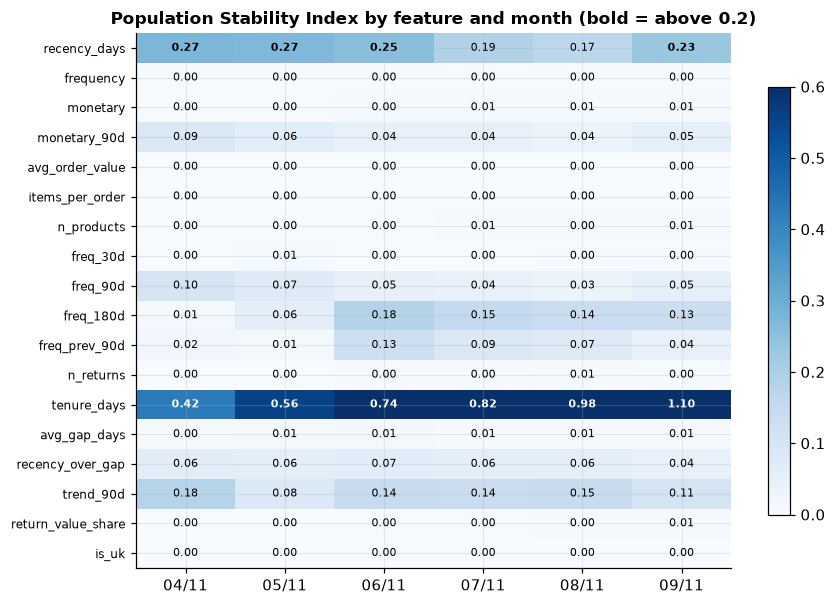

features above 0.2 in at least one month: {'recency_days': 4, 'tenure_days': 6}


In [3]:
def psi(reference, current, bins=10):
    """Population Stability Index of one feature: how far the current distribution has moved from the reference one."""
    reference, current = reference.dropna(), current.dropna()
    if reference.nunique() <= 2:                                    # a binary flag: compare the two categories directly
        edges, a, b = None, reference.value_counts(normalize=True), current.value_counts(normalize=True).reindex(reference.value_counts(normalize=True).index).fillna(0)
        a, b = a.clip(lower=1e-4), b.clip(lower=1e-4)
        return float(((b - a) * np.log(b / a)).sum())
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    a = np.clip(np.histogram(reference, edges)[0] / len(reference), 1e-4, None)
    b = np.clip(np.histogram(current, edges)[0] / len(current), 1e-4, None)
    return float(((b - a) * np.log(b / a)).sum())

drift = pd.DataFrame({c.date(): {f: psi(train[f], history[c][0][f]) for f in F} for c in months})

fig, ax = plt.subplots(figsize=(8.2, 5.6))
im = ax.imshow(drift.to_numpy(), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(drift.columns)), [str(c)[5:7] + "/" + str(c)[2:4] for c in drift.columns]); ax.set_yticks(range(len(drift.index)), drift.index, fontsize=8)
for i in range(drift.shape[0]):
    for j in range(drift.shape[1]):
        v = drift.iat[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black", fontweight="bold" if v > 0.2 else "normal")
ax.set(title="Population Stability Index by feature and month (bold = above 0.2)"); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
alarms = (drift > 0.2).sum(axis=1); print("features above 0.2 in at least one month:", {f: int(n) for f, n in alarms[alarms > 0].items()})

**Reading the heatmap.** Two things stand out.

1. **Almost everything is stable.** Of eighteen features only two ever cross 0.2.
2. **Neither alarm is the story.** `tenure_days` alarms in *every* month, and that is built in: tenure is the days since a customer's first order, so every customer's tenure grows by a month each month and the distribution has to move. `recency_days` crosses the line in four months, including the spring months when nothing was wrong, so September does not stand out from April.

PSI is working as designed. It tells us the *kinds of customer* in front of us have changed, and they have not: the same sorts of customers simply behaved differently. **Input drift cannot see a change in behaviour.**

## Layer 2: has the behaviour changed? The early-label monitor

Inputs cannot see a change in *behaviour*: the same customers with the same histories simply buy more. For that we need outcomes, and the full outcome takes 90 days. But we do not have to wait for all of it. **The share of the cohort that has already bought again after 30 days** is a *partial label*, available 60 days earlier. We compare it with what that number looked like in the reference months, as a z-score (how many standard deviations from normal).

<div class="admonition warning">
<p class="admonition-title">A small reference sample</p>
<p>We have only four reference months to learn what "normal" is, so the standard deviation below is itself poorly known. Treat the z-scores as a rough guide, not a precise probability. In a real deployment you would build the reference from a longer history.</p>
</div>

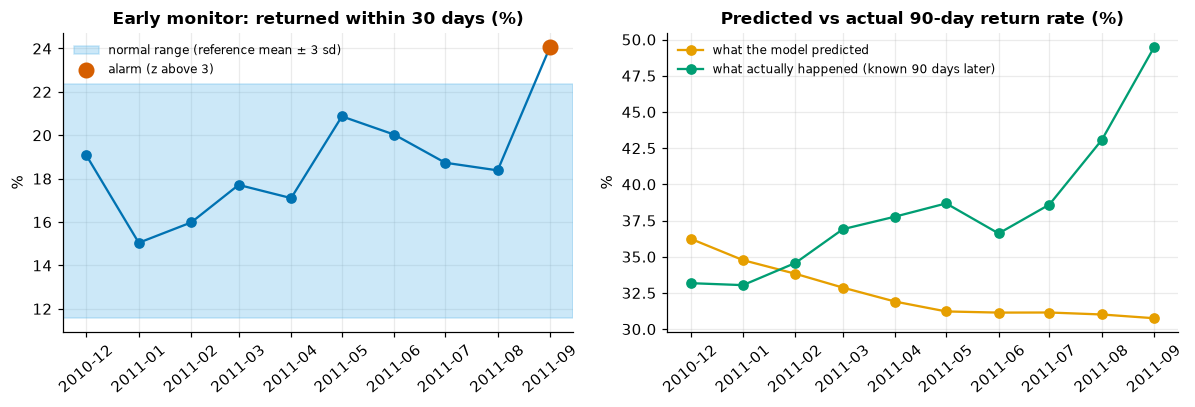

,early 30-day rate,z-score,available on,full 90-day rate,z of full rate,full outcome on
2011-04-01,17.1%,+0.1,2011-05-01,37.8%,+1.9,2011-06-30
2011-05-01,20.9%,+2.2,2011-05-31,38.7%,+2.4,2011-07-30
2011-06-01,20.0%,+1.7,2011-07-01,36.6%,+1.2,2011-08-30
2011-07-01,18.7%,+1.0,2011-07-31,38.6%,+2.3,2011-09-29
2011-08-01,18.4%,+0.8,2011-08-31,43.1%,+4.8,2011-10-30
2011-09-01,24.1%,+4.0,2011-10-01,49.5%,+8.4,2011-11-30


In [4]:
rates = table[["early return, 30 days", "actual return, 90 days", "mean predicted return"]].copy()
ref_rows = [c.date() for c in reference_cutoffs]
mu, sd = rates.loc[ref_rows].mean(), rates.loc[ref_rows].std()
z = (rates - mu) / sd
available = pd.Series({c.date(): (c + pd.Timedelta(days=30)).date() for c in reference_cutoffs + months}, name="early signal available on")
full_available = pd.Series({c.date(): (c + pd.Timedelta(days=90)).date() for c in reference_cutoffs + months}, name="full outcome available on")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
x = [c.date() for c in reference_cutoffs + months]
a.axhspan((mu["early return, 30 days"] - 3 * sd["early return, 30 days"]) * 100, (mu["early return, 30 days"] + 3 * sd["early return, 30 days"]) * 100, color=style.SKY, alpha=0.3, label="normal range (reference mean ± 3 sd)")
a.plot(x, rates["early return, 30 days"] * 100, marker="o", color=style.BLUE)
alarm_x = [d for d in x if z.loc[d, "early return, 30 days"] > 3]
a.scatter(alarm_x, [rates.loc[d, "early return, 30 days"] * 100 for d in alarm_x], color=style.RED, s=90, zorder=5, label="alarm (z above 3)")
a.set(title="Early monitor: returned within 30 days (%)", ylabel="%"); a.tick_params(axis="x", rotation=40); a.legend(loc="upper left", fontsize=8)
b.plot(x, rates["mean predicted return"] * 100, marker="o", color=style.ORANGE, label="what the model predicted")
b.plot(x, rates["actual return, 90 days"] * 100, marker="o", color=style.GREEN, label="what actually happened (known 90 days later)")
b.set(title="Predicted vs actual 90-day return rate (%)", ylabel="%"); b.tick_params(axis="x", rotation=40); b.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

timeline = pd.DataFrame({"early 30-day rate": rates["early return, 30 days"].map("{:.1%}".format), "z-score": z["early return, 30 days"].map("{:+.1f}".format),
                         "available on": available, "full 90-day rate": rates["actual return, 90 days"].map("{:.1%}".format),
                         "z of full rate": z["actual return, 90 days"].map("{:+.1f}".format), "full outcome on": full_available}).loc[[c.date() for c in months]]
timeline

**Reading the chart and the table.** The September cohort's early return rate jumps well outside the normal band and crosses the alarm line (z about +4), and **that is known on 1 October**. The other months, including a mild bump in May, stay inside it.

Compare when each signal could have fired. The early rate for September arrives on 1 October. The first *full* outcome to cross the alarm line belongs to the August cohort and arrives on 30 October (z about +4.8, and its window already reached into the September upswing). September's own full outcome, the one the test verdict measured, arrives on 30 November (z about +8.4). So the early partial label gave a warning **four weeks before any full outcome showed it, and two months before the full September figure**.

The right-hand chart shows the model's side of the story: its average prediction stays near 31% while reality climbs, so the *gap* is the signal, and the gap can only be measured once outcomes arrive.

## Layer 3: is the model still earning its keep? The benchmark guard

The previous page ended with a rule: ship the model **with the simple rule alongside as a benchmark**. Now we use it. Each month, once outcomes mature, score both on the same customers and compare revenue protected within 200 calls. If the model stops matching the rule, it is not earning its keep.

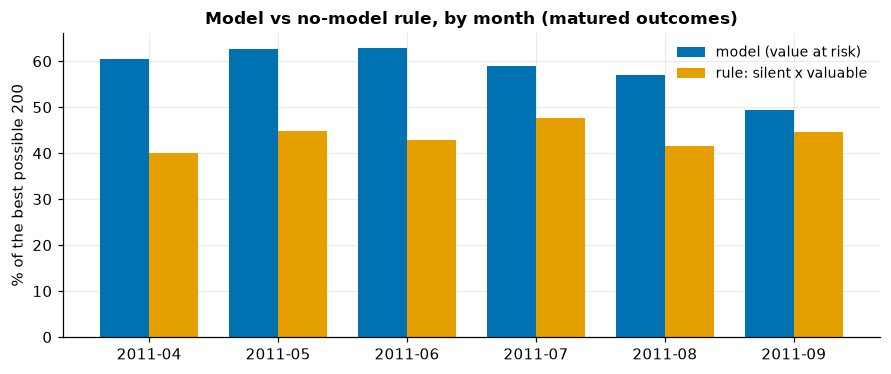

,"model, % of best possible","rule, % of best possible",model minus rule (£),model ahead in
cutoff,,,,
2011-04-01,60.4%,40.0%,"+190,920",100%
2011-05-01,62.7%,44.9%,"+146,833",100%
2011-06-01,62.9%,42.9%,"+181,710",100%
2011-07-01,59.0%,47.7%,"+107,316",99%
2011-08-01,56.9%,41.6%,"+118,224",99%
2011-09-01,49.3%,44.7%,"+32,252",88%


In [5]:
guard = []
for c in months:
    snap, p, _ = history[c]
    v = snap["monetary"].to_numpy()
    model_risk, rule_risk = (1 - p) * v, (pct(snap["recency_days"]) * pct(snap["monetary"])).to_numpy()
    m = at_risk_report(snap["y"], None, snap["monetary"], risk=model_risk)
    r = at_risk_report(snap["y"], None, snap["monetary"], risk=rule_risk)
    d = bootstrap_difference(snap["y"], v, model_risk, rule_risk, metric="revenue@200", n_boot=150, seed=0)
    guard.append({"cutoff": c.date(), "model, % of best possible": m["revenue@200 % of oracle"], "rule, % of best possible": r["revenue@200 % of oracle"],
                  "model minus rule (£)": d["mean"], "model ahead in": d["share_a_better"]})
guard = pd.DataFrame(guard).set_index("cutoff")
fig, ax = plt.subplots(figsize=(8.2, 3.5))
xs = np.arange(len(guard)); w = 0.38
ax.bar(xs - w / 2, guard["model, % of best possible"] * 100, w, color=style.BLUE, label="model (value at risk)")
ax.bar(xs + w / 2, guard["rule, % of best possible"] * 100, w, color=style.ORANGE, label="rule: silent x valuable")
ax.set_xticks(xs, [str(c)[:7] for c in guard.index]); ax.set(ylabel="% of the best possible 200", title="Model vs no-model rule, by month (matured outcomes)"); ax.legend()
plt.tight_layout(); plt.show()
guard.assign(**{"model, % of best possible": guard["model, % of best possible"].map("{:.1%}".format), "rule, % of best possible": guard["rule, % of best possible"].map("{:.1%}".format),
                "model minus rule (£)": guard["model minus rule (£)"].map("{:+,.0f}".format), "model ahead in": guard["model ahead in"].map("{:.0%}".format)})

**Reading the guard.** From April to August the model protects far more than the rule (by roughly £110,000 to £190,000 a month, ahead in 99% to 100% of resamples). Then its lead **shrinks**, and in September it is down to about £32,000, ahead in only about 88% of resamples: no longer distinguishable from the free rule. That matches the test verdict on the previous page.

A policy of "model behind the rule two months running" would not yet have fired, because the model was never *behind*. But the **narrowing margin** is itself a trend worth alerting on, and it is one more sign that September was different. (Revenue is noisy, so judge the trend over several months, not one.)

## The calendar was the earliest warning of all

One more monitor needs no model at all: **last year's pattern**. The business has a strong seasonal cycle (Page 4), and we have a full autumn on record from 2010.

In [6]:
orders = inv.groupby(inv["date"].dt.to_period("M")).size()
seasonal = pd.DataFrame({"2010 orders": [orders[f"2010-{m:02d}"] for m in (8, 9, 10)], "2011 orders": [orders[f"2011-{m:02d}"] for m in (8, 9, 10)]}, index=["August", "September", "October"])
seasonal["2010: change on August"] = seasonal["2010 orders"] / seasonal.loc["August", "2010 orders"] - 1
seasonal["2011: change on August"] = seasonal["2011 orders"] / seasonal.loc["August", "2011 orders"] - 1
seasonal.assign(**{c: seasonal[c].map("{:+.0%}".format) for c in seasonal.columns if "change" in c})

,2010 orders,2011 orders,2010: change on August,2011: change on August
August,1272,1265,+0%,+0%
September,1653,1734,+30%,+37%
October,2103,1888,+65%,+49%


**Reading the table.** August was flat year on year (about 1,270 orders both times), and then the **same climb repeated**: September up 30% on August in 2010 and 37% in 2011, October up 65% and 49%. The autumn surge was not a surprise in 2011; it was sitting in the 2010 data. A **seasonal expectation** ("the base rate rises from September") would have warned us before a single September order arrived, and before any statistical monitor could fire. When the cycle is regular, the calendar is the cheapest and earliest monitor you have.

## An alert policy

Monitors are only useful if they lead to action. Here is how the signals above combine into a policy a team could run:

| Signal | Threshold | Severity | Action |
|---|---|---|---|
| Data-quality checks (Page 2) | any `FAIL` | **Stop** | do not score; fix the feed |
| Early 30-day return rate | z above 3 | **Warn** | flag probabilities as unreliable; widen the call list or fall back to the rule's ordering |
| Matured calibration gap | actual minus predicted above 10 points | **Warn** | recalibrate (below) |
| Benchmark guard | model behind the rule two months running | **Review** | investigate; consider switching to the rule |
| Seasonal calendar | a known peak or event approaching | **Plan** | schedule a recalibration or a seasonal adjustment *before* it |
| Input drift (PSI) | above 0.2 on a feature that is *not* structurally trending | **Note** | investigate, but do not page anyone |

## A remedy, and why it comes too late

When the new return rate is finally known, a small repair fixes the probabilities without touching the ranking: **recalibration**. Fit a one-line correction (a slope and intercept on the log-odds scale) that maps the model's scores to the observed rate. To keep it honest we fit on a random half of the test customers and judge on the other half.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

shipped = models.make_logistic().fit(pd.concat([train, valid])[F], pd.concat([train, valid])["y"])      # the model we shipped on the last page
p_raw = shipped.predict_proba(test[F])[:, 1]
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

rng = np.random.default_rng(0)
half = rng.random(len(test)) < 0.5                                   # fit the correction on one half ...
fixer = LogisticRegression(C=1e6).fit(logit(p_raw[half]).reshape(-1, 1), test["y"].to_numpy()[half])
p_fixed = fixer.predict_proba(logit(p_raw).reshape(-1, 1))[:, 1]
judge = ~half                                                        # ... and judge it on the other half

before_after = pd.DataFrame({
    "average predicted": [p_raw[judge].mean(), p_fixed[judge].mean()],
    "actually returned": [test["y"].to_numpy()[judge].mean()] * 2,
    "Brier score": [brier_score_loss(test["y"].to_numpy()[judge], p_raw[judge]), brier_score_loss(test["y"].to_numpy()[judge], p_fixed[judge])],
    "AUC (ranking)": [roc_auc_score(test["y"].to_numpy()[judge], p_raw[judge]), roc_auc_score(test["y"].to_numpy()[judge], p_fixed[judge])],
}, index=["as shipped", "recalibrated"])
before_after.assign(**{"average predicted": before_after["average predicted"].map("{:.1%}".format), "actually returned": before_after["actually returned"].map("{:.1%}".format),
                       "Brier score": before_after["Brier score"].map("{:.3f}".format), "AUC (ranking)": before_after["AUC (ranking)"].map("{:.3f}".format)})

,average predicted,actually returned,Brier score,AUC (ranking)
as shipped,31.8%,48.7%,0.225,0.763
recalibrated,49.9%,48.7%,0.195,0.763


**Reading the repair.** On the half of customers we did not use for fitting, the shipped model predicted about 32% against an actual 49%. After recalibration the average prediction is within about a point of the truth and the Brier score improves from roughly 0.225 to 0.195, while the **AUC is identical**: the ranking is untouched, which is why the call list was never wrong, only the odds.

But note *when* this fix becomes possible. It needs to know the new return rate, which the September cohort only revealed on 30 November. For the September calls it comes too late. That is the point of the earlier layers: the early-label monitor and the calendar could have triggered this correction, or a seasonal adjustment, **before** the calls were made.

## When to retrain

| Policy | Trigger | Use when |
|---|---|---|
| **Scheduled** | every quarter, once the previous quarter's outcomes have matured | behaviour changes slowly and predictably |
| **Triggered** | a Warn or Review alert from the table above | behaviour can change suddenly |
| **Seasonal** | before a known peak | the cycle is regular (ours is) |

Whatever the trigger, a retrained model passes through the **same gates** as the first one: the time-ordered split, the embargo, the baselines, the paired comparison against the incumbent *and* the rule, and a fresh test on data it has never seen. Keep the previous version, its card and its hash, so a bad release can be rolled back in minutes.

## Check yourself

<details class="question">
<summary>1. The input-drift report (PSI) did not single out the September shift. Does that mean PSI is useless?</summary>

No, it means PSI answers a different question. It tells you when the *customers' features* have changed, which catches broken feeds and shifting populations. In September the same kinds of customer behaved differently, so the inputs looked as they did before while the outcomes changed. That is why you need outcome-based monitors (early labels, matured calibration) alongside input monitors, not instead of them.

</details>

<details class="question">
<summary>2. <code>tenure_days</code> shows high drift every single month. Is that a problem?</summary>

No, and it is a useful false alarm to learn from. Tenure is the number of days since a customer's first order, so *every* customer's tenure grows by a month each month: the distribution must move, by construction. A monitor that cries wolf every month teaches people to ignore it. Either exclude features that trend by definition, or compare against the same period last year instead of against a fixed reference.

</details>

<details class="question">
<summary>3. Why not just wait for the full 90-day outcome, which is the most reliable signal?</summary>

Because it arrives after a complete cycle of decisions has been made on the wrong probabilities. The early 30-day rate is noisier but arrives two months sooner, and its job is to raise a flag so someone looks, not to prove anything. Good monitoring trades some certainty for time, and uses the slow, reliable signal to confirm.

</details>

## Exercise

<details class="question">
<summary>The early-signal alarm uses z above 3. How many months would have been flagged at z above 2, and what is the cost of the lower threshold? Predict first.</summary>

```python
early_z = z["early return, 30 days"]
for threshold in (2, 3):
    flagged = [str(d)[:7] for d in early_z.index if d in [c.date() for c in months] and early_z[d] > threshold]
    print(f"z > {threshold}: {flagged}")
```

At z above 2, two months are flagged: May and September. At z above 3, only September. May's early rate ran about 2.2 standard deviations above normal, and its full outcome also ended up elevated (about +2.4), so it was a mild genuine uptick rather than noise, but far too small to act on. The lower threshold buys **sensitivity** (you would catch a smaller shift sooner) at the cost of **more alerts to triage**, and with only four reference months the threshold itself is uncertain. Choose it by how costly a missed shift is compared with how costly a false alarm is.

</details>

## Recap

- A shipped model does not crash when the world changes; it quietly gets worse. Monitoring is how you notice.
- Watch at several layers: **data quality**, **inputs**, **outputs**, **outcomes** and a **benchmark**. No single one is enough.
- **Input drift cannot see a change in behaviour.** PSI did not single out the autumn shift, and a structurally trending feature (tenure) raised a false alarm every month.
- Outcomes arrive late, so build **early partial-label monitors** that trade certainty for time, and use **the calendar and last year's pattern** as the earliest warning of all.
- Keep a **free benchmark** (here the rule) running alongside the model.
- Recalibration repairs probabilities without touching the ranking, but it needs outcomes you will only have later. Plan retraining (scheduled, triggered and seasonal) through the **same gates** as the first release.

**Next:** *Reproducibility and project hygiene*, the last page of the lifecycle: making all of this repeatable, testable and handed over cleanly.